In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
columns = [
    "symboling", "normalized-losses", "make", "fuel-type",
    "aspiration", "num-of-doors", "body-style", "drive-wheels",
    "engine-location", "wheel-base", "length", "width", "height",
    "curb-weight", "engine-type", "num-of-cylinders",
    "engine-size", "fuel-system", "bore", "stroke",
    "compression-ratio", "horsepower", "peak-rpm",
    "city-mpg", "highway-mpg", "price"
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"

df = pd.read_csv(
    url,
    names=columns,
    na_values="?"
)

print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)

First 5 rows:


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


Dataset shape: (205, 26)


In [3]:
numeric_cols = [
    "symboling", "normalized-losses", "wheel-base",
    "length", "width", "height", "curb-weight",
    "engine-size", "bore", "stroke", "compression-ratio",
    "horsepower", "peak-rpm", "city-mpg",
    "highway-mpg", "price"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

df["num-of-doors"] = df["num-of-doors"].fillna(
    df["num-of-doors"].mode()[0]
)

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Data cleaned successfully!")

Missing values after cleaning: 0
Data cleaned successfully!


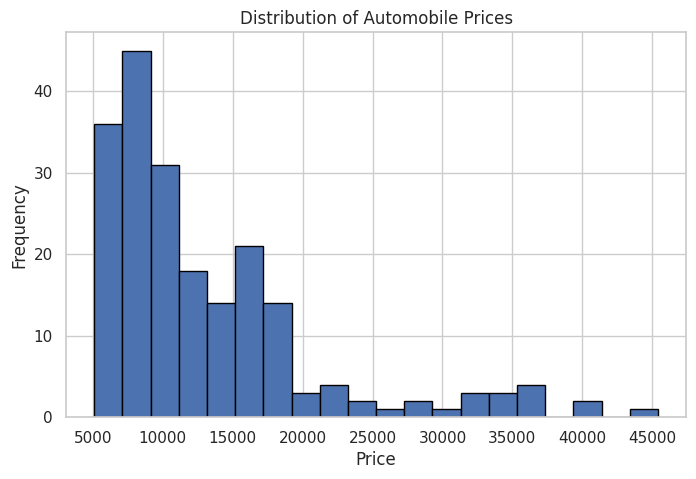

In [4]:
plt.figure(figsize=(8, 5))
plt.hist(df["price"], bins=20, edgecolor="black")
plt.title("Distribution of Automobile Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

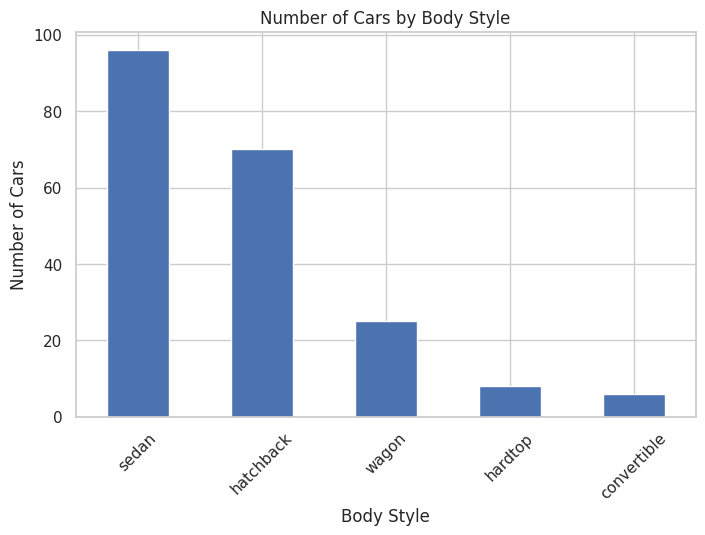

In [5]:
plt.figure(figsize=(8, 5))
df["body-style"].value_counts().plot(kind="bar")
plt.title("Number of Cars by Body Style")
plt.xlabel("Body Style")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.show()

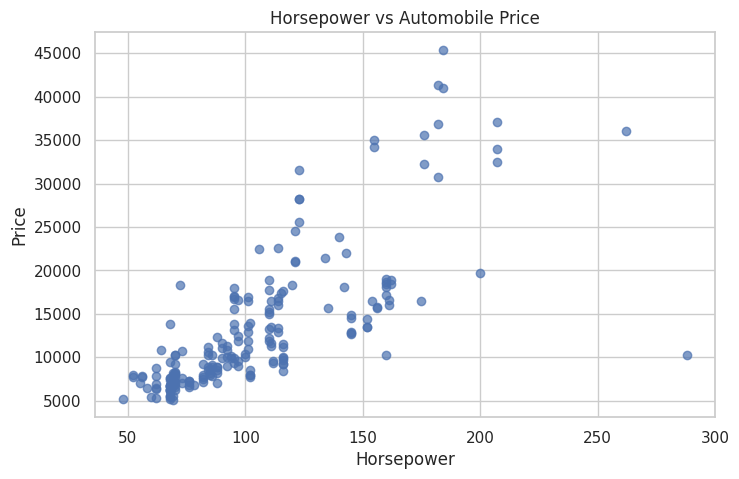

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(df["horsepower"], df["price"], alpha=0.7)
plt.title("Horsepower vs Automobile Price")
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.show()

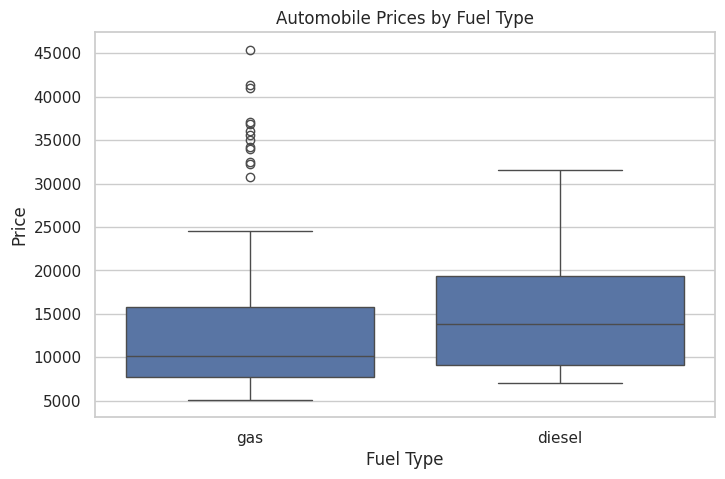

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="fuel-type", y="price")
plt.title("Automobile Prices by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price")
plt.show()

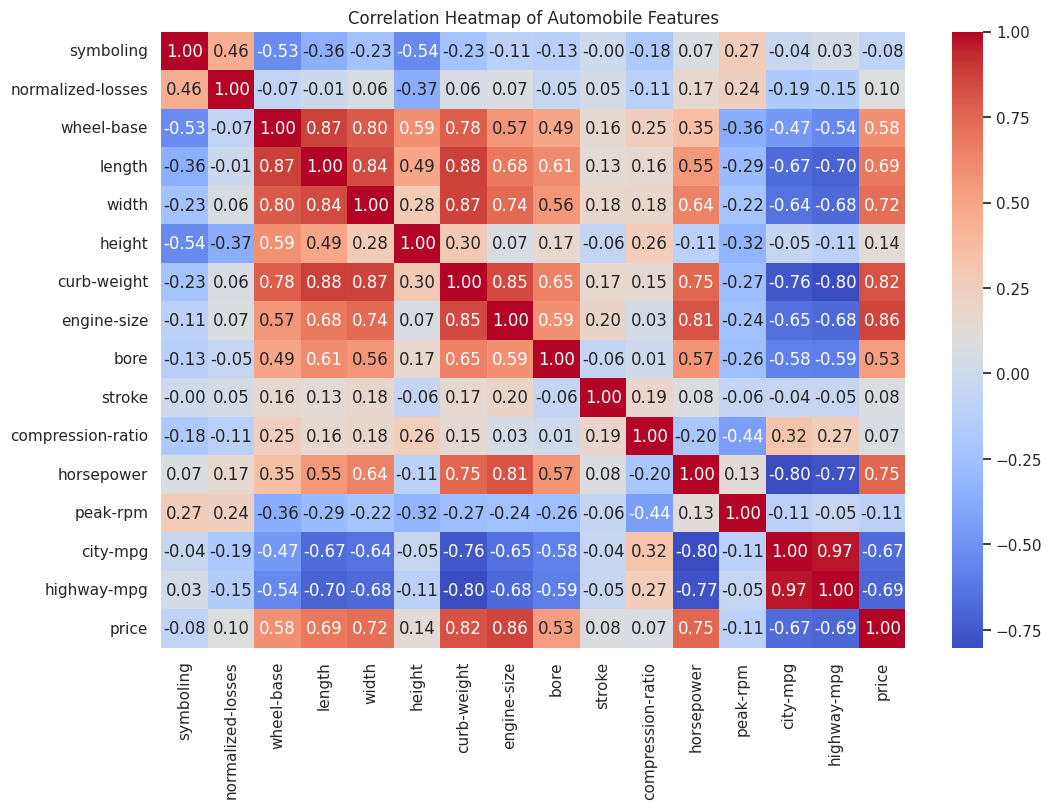

In [8]:
plt.figure(figsize=(12, 8))

correlation = df[numeric_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Automobile Features")
plt.show()

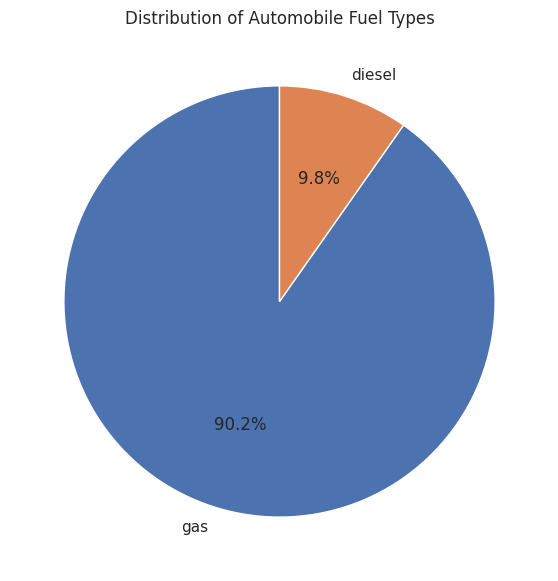

In [9]:
plt.figure(figsize=(7, 7))

df["fuel-type"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Automobile Fuel Types")
plt.ylabel("")
plt.show()

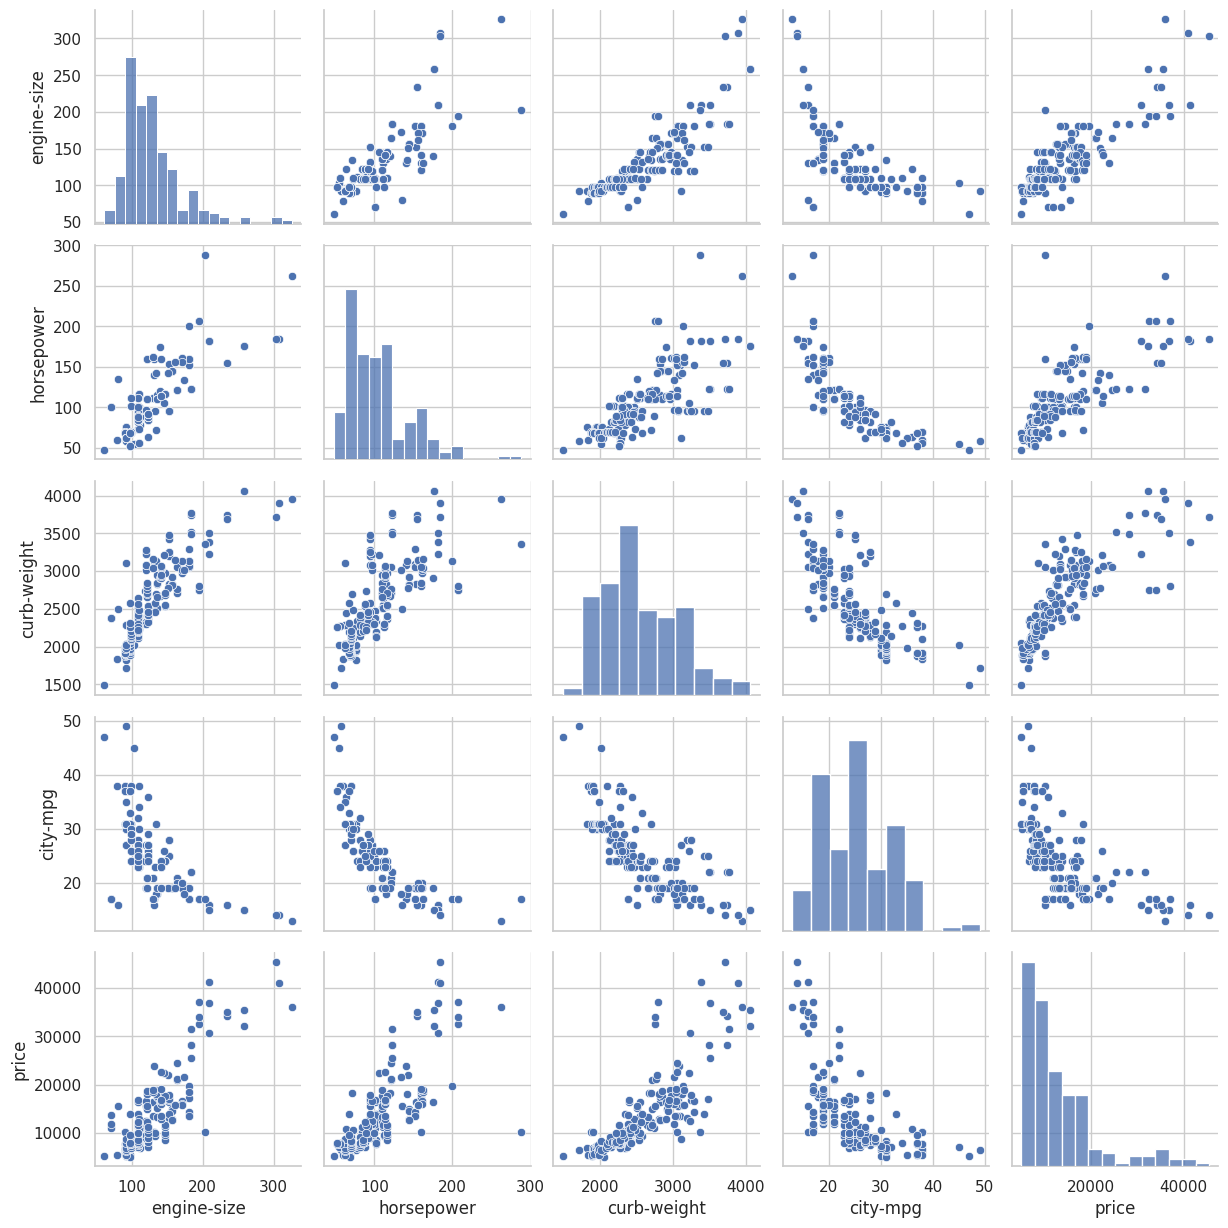

In [10]:
sns.pairplot(
    df[["engine-size", "horsepower", "curb-weight",
        "city-mpg", "price"]]
)

plt.show()

In [11]:
display(df.describe())

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,0.834146,120.600000,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329366,3.256098,10.142537,104.165854,5126.097561,25.219512,30.751220,13150.307317
std,1.245307,31.805105,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270858,0.313634,3.972040,39.529733,477.035772,6.542142,6.886443,7879.121326
min,-2.000000,65.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,0.000000,101.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,1.000000,115.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,2.000000,137.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000
max,3.000000,256.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000
